# Device-level noise

The "Noisy simulation" tutorial placed Pauli and coherent errors after gates. Real devices do more: qubits relax towards $|0\rangle$, two-qubit gates disturb their neighbours, waiting qubits keep decohering, and states are prepared and read out imperfectly. In this tutorial you will build such a device noise model, check it against an exact density matrix, find which error source matters most, and see why relaxation and coherent crosstalk cannot be replaced by simpler Pauli noise.

## Setup

In [1]:
import time

import matplotlib.pyplot as plt
import numpy as np
from qibo import gates

from mpstab import HSMPO
from mpstab.hamiltonians import pauli_string_to_hamiltonian
from mpstab.models.ansatze import ParametricKickedIsing
from mpstab.models.noise import (
    CoherentError,
    DepolarizingError,
    NoiseModel,
    PauliError,
    ReadoutError,
    StatePreparationError,
    ThermalRelaxationError,
)
from mpstab.plotting import COLORS, set_style

set_style()

## The circuit and the observables

As in the first noise tutorial, we use three steps of a kicked Ising chain on 8 qubits, whose two-qubit gates are CNOTs. We look at two observables: the nearest-neighbour energy $H = \sum_i Z_iZ_{i+1}$, and the magnetization $M = \frac1n\sum_i Z_i$, on which relaxation acts most directly.

In [2]:
NQUBITS = 8
ansatz = ParametricKickedIsing(nqubits=NQUBITS, n_steps=3, delta_h=0.2)
circuit = ansatz.circuit
hsmpo = HSMPO(ansatz, progress=False)


def z_string(*sites, n=NQUBITS):
    return "".join("Z" if q in sites else "I" for q in range(n))


energy = {z_string(i, i + 1): 1.0 for i in range(NQUBITS - 1)}
magnetization = {z_string(i): 1.0 / NQUBITS for i in range(NQUBITS)}

print(f"noiseless <H> = {hsmpo.expectation(energy):+.5f}")
print(f"noiseless <M> = {hsmpo.expectation(magnetization):+.5f}")

noiseless <H> = +0.56761
noiseless <M> = -0.06829


## A device noise model

The qubits sit on a line. Times are in microseconds, with values typical of superconducting devices: $T_1 = 100$, $T_2 = 80$, single-qubit gates of 30 ns and CNOTs of 80 ns. Besides `add`, two more rules place errors where devices put them:

| source | error | rule |
|---|---|---|
| relaxation during gates | `ThermalRelaxationError(t1, t2, time)` | `add`, after every gate |
| two-qubit gate error | `DepolarizingError` | `add`, after every CNOT |
| crosstalk | coherent $ZZ$ between a CNOT qubit and its neighbours | `add_crosstalk(error, coupling, gate)` |
| idling | relaxation, and a residual $ZZ$ on idle coupled pairs | `add_idle(error, coupling=...)` |
| preparation and readout | `StatePreparationError(p)`, `ReadoutError(p0, p1)` with $p_{0\to1} < p_{1\to0}$ | `add`, without a gate |

`add_idle` acts on the qubits left idle in each *moment* (layer) of the circuit. A coherent error costs about as much as a magic gate, so for the always-on idle $ZZ$ we use `CoherentError.twirled()`, the stochastic error it becomes under randomized compiling or dynamical decoupling.

We wrap the model in a function, so that later we can switch sources on one at a time, and replace an error by its Pauli twirl (the Pauli channel with the same diagonal, which `pauli_twirl` computes from the Kraus operators).

In [3]:
T1, T2 = 100.0, 80.0       # microseconds
T_1Q, T_2Q = 0.03, 0.08    # gate durations
LINE = [(q, q + 1) for q in range(NQUBITS - 1)]
SOURCES = ("relaxation", "gate", "crosstalk", "idle", "spam")
PAULIS = {"X": np.array([[0, 1], [1, 0]]), "Y": np.array([[0, -1j], [1j, 0]]), "Z": np.diag([1, -1])}


def pauli_twirl(error):
    return PauliError({p: float(sum(abs(np.trace(m @ k)) ** 2 for k in error.kraus) / 4)
                       for p, m in PAULIS.items()})


def device_noise(sources=SOURCES, crosstalk=0.03, coupling=LINE,
                 twirl_relaxation=False, twirl_crosstalk=False):
    def relax(time):
        error = ThermalRelaxationError(T1, T2, time)
        return pauli_twirl(error) if twirl_relaxation else error

    zz = CoherentError("ZZ", crosstalk)
    noise = NoiseModel()
    if "relaxation" in sources:
        noise.add(relax(T_1Q), (gates.RX, gates.RZ, gates.H))
        noise.add(relax(T_2Q), gates.CNOT)
    if "gate" in sources:
        noise.add(DepolarizingError(5e-3), gates.CNOT)
    if "crosstalk" in sources:
        noise.add_crosstalk(zz.twirled() if twirl_crosstalk else zz, coupling, gates.CNOT)
    if "idle" in sources:
        noise.add_idle(relax(T_2Q))
        noise.add_idle(CoherentError("ZZ", 0.02).twirled(), coupling=coupling)
    if "spam" in sources:
        noise.add(StatePreparationError(0.005))
        noise.add(ReadoutError(0.01, 0.03))
    return noise


noise = device_noise()
print(len(noise.events(circuit)), "errors inserted in the circuit")

926 errors inserted in the circuit


## Checking against the exact density matrix

`noise.apply(circuit)` gives the same noisy circuit as a qibo density-matrix circuit, and `noise.readout_observable` folds the readout errors into the observable. Together they give the exact value on small systems.

In [4]:
def exact_expectation(noise, observable):
    constant, terms = noise.readout_observable(observable, NQUBITS)
    rho = noise.apply(circuit)().state()
    return constant + sum(
        c * pauli_string_to_hamiltonian(p).expectation_from_state(rho) for p, c in terms.items()
    )


start = time.perf_counter()
result = hsmpo.noisy_expectation(energy, noise, n_samples=300, seed=0)
elapsed = time.perf_counter() - start

print(f"noiseless <H> = {hsmpo.expectation(energy):+.5f}")
print(f"mpstab    <H> = {result.mean:+.5f} ± {result.stderr:.5f}   ({elapsed:.0f} s)")
print(f"exact     <H> = {exact_expectation(noise, energy):+.5f}")

noiseless <H> = +0.56761
mpstab    <H> = +0.61633 ± 0.00552   (39 s)


exact     <H> = +0.62524


The two agree within the statistical error. The error bar is larger than for Pauli noise: the non-Pauli part of relaxation turns the sampled average into a quasi-probability average, as explained at the end of this tutorial. More samples (`n_samples`) shrink it.

## Relaxation is not a Pauli channel

Relaxation pushes every qubit towards $|0\rangle$, so it is not a Pauli channel. A common shortcut replaces it by its *Pauli twirl*, the Pauli channel with the same diagonal. The twirl keeps the loss of coherence but drops the drift towards $|0\rangle$. `mpstab` simulates the full channel, so we can see the difference: below we keep only relaxation during gates, make it longer with `noise.scaled`, and follow the magnetization.

In [5]:
relaxation = device_noise(sources=("relaxation",))
twirled = device_noise(sources=("relaxation",), twirl_relaxation=True)

factors = np.array([0, 4, 8, 12])
curves = {}
for name, model in (("thermal relaxation", relaxation), ("Pauli twirl", twirled)):
    curves[name] = [hsmpo.noisy_expectation(magnetization, model.scaled(f), n_samples=1000, seed=0)
                    for f in factors]
exact_curve = [exact_expectation(relaxation.scaled(f), magnetization) for f in factors]

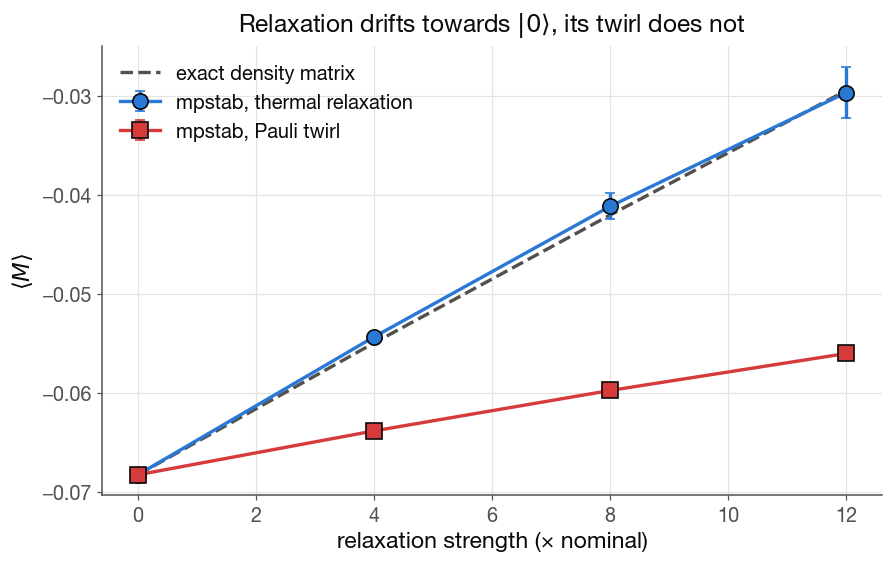

In [6]:
fig, ax = plt.subplots()
ax.plot(factors, exact_curve, "--", color=COLORS["gray"], label="exact density matrix")
for (name, results), marker in zip(curves.items(), ("o", "s")):
    ax.errorbar(factors, [r.mean for r in results], yerr=[r.stderr for r in results],
                fmt=marker + "-", label=f"mpstab, {name}")
ax.set_xlabel("relaxation strength (× nominal)")
ax.set_ylabel(r"$\langle M \rangle$")
ax.set_title("Relaxation drifts towards $|0\\rangle$, its twirl does not")
ax.legend()
plt.show()

The error bars of the full channel grow with the relaxation strength. That is the price of its non-Pauli part, explained at the end of this tutorial: it turns the sampled average into a quasi-probability average, whose variance grows quickly with the strength of the channel.

## Error budget

Which source matters most? We switch the sources on one at a time and compare the shift of the energy from its noiseless value. Each source alone takes only a second or two; the full model costs more, because errors at different locations combine.

In [7]:
ideal_energy = hsmpo.expectation(energy)
shifts, errors, exact_shifts = [], [], []
for source in SOURCES:
    alone = device_noise(sources=(source,))
    result = hsmpo.noisy_expectation(energy, alone, n_samples=500, seed=1)
    shifts.append(result.mean - ideal_energy)
    errors.append(result.stderr)
    exact_shifts.append(exact_expectation(alone, energy) - ideal_energy)

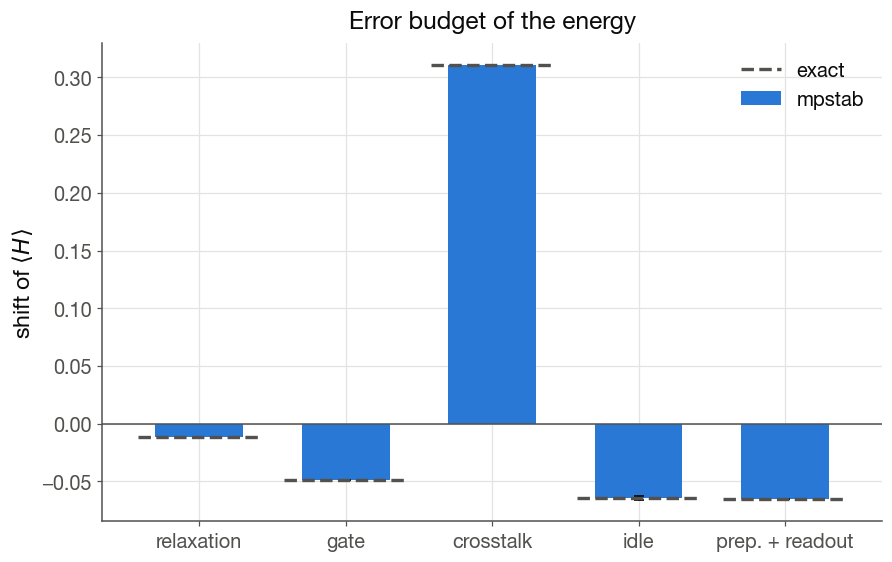

In [8]:
fig, ax = plt.subplots()
x = np.arange(len(SOURCES))
ax.bar(x, shifts, yerr=errors, width=0.6, label="mpstab")
ax.hlines(exact_shifts, x - 0.42, x + 0.42, color=COLORS["gray"], ls="--", label="exact")
ax.axhline(0, color=COLORS["gray"], lw=1)
ax.set_xticks(x, ["relaxation", "gate", "crosstalk", "idle", "prep. + readout"])
ax.set_ylabel(r"shift of $\langle H \rangle$")
ax.set_title("Error budget of the energy")
ax.legend()
plt.show()

## Coherent or twirled crosstalk?

The coherent crosstalk dominates the budget. That is no accident: the couplings of this circuit are themselves $ZZ$ rotations, so a spurious $ZZ$ on a neighbouring pair shifts the Ising angles directly, and these shifts add up coherently, in amplitude, step after step.

Randomized compiling turns the same error into its Pauli twirl, a stochastic $ZZ$ flip with probability $\sin^2(\theta/2)$, which only adds up in probability. Sweeping the crosstalk angle $\theta$ shows the difference: the coherent shift grows like $\theta$, the twirled one like $\theta^2$.

In [9]:
angles = np.array([0.005, 0.01, 0.02, 0.04, 0.08])
coherent, twirl = [], []
for theta in angles:
    for twirl_crosstalk, values in ((False, coherent), (True, twirl)):
        model = device_noise(sources=("crosstalk",), crosstalk=theta, twirl_crosstalk=twirl_crosstalk)
        values.append(hsmpo.noisy_expectation(energy, model).mean)

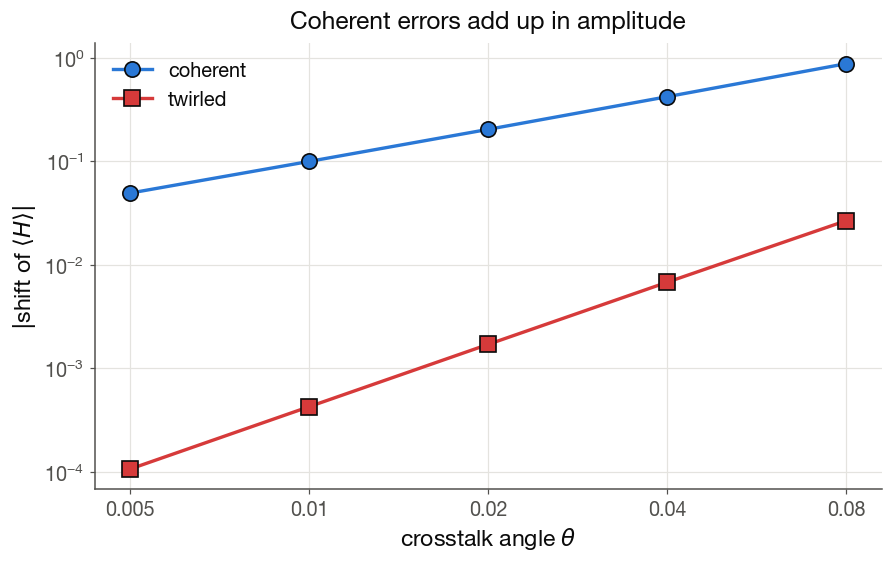

In [10]:
fig, ax = plt.subplots()
ax.loglog(angles, np.abs(np.array(coherent) - ideal_energy), "o-", label="coherent")
ax.loglog(angles, np.abs(np.array(twirl) - ideal_energy), "s-", label="twirled")
ax.set_xticks(angles, [f"{a:g}" for a in angles], minor=False)
ax.minorticks_off()
ax.set_xlabel(r"crosstalk angle $\theta$")
ax.set_ylabel(r"$|$shift of $\langle H \rangle|$")
ax.set_title("Coherent errors add up in amplitude")
ax.legend()
plt.show()

The twirled error is also cheaper to simulate: every coherent rotation joins the chain of magic rotations, while a stochastic error leaves it alone.

## Beyond density matrices

The device model runs unchanged on chains no density matrix can hold. Two choices keep it cheap: we twirl the crosstalk, as randomized compiling would, so it does not lengthen the rotation chain; and we leave idling out, because this ansatz queues its couplings as a staircase, so its depth (and the number of idle windows) grows with $n$. We measure a local $Z_iZ_{i+1}$ in the middle of the chain, whose light cone has a fixed size.

In [11]:
print(" n    errors   noiseless   noisy              time")
for n in (16, 60):
    surrogate = HSMPO(ParametricKickedIsing(nqubits=n, n_steps=3, delta_h=0.2),
                      max_bond_dimension=32, progress=False)
    line = [(q, q + 1) for q in range(n - 1)]
    model = device_noise(sources=("relaxation", "gate", "crosstalk", "spam"),
                         coupling=line, twirl_crosstalk=True)
    local = z_string(n // 2, n // 2 + 1, n=n)
    start = time.perf_counter()
    result = surrogate.noisy_expectation(local, model, n_samples=500, seed=3)
    print(f"{n:3d}   {len(model.events(surrogate.ansatz.circuit)):5d}    {surrogate.expectation(local):+.4f}"
          f"     {result.mean:+.4f} ± {result.stderr:.4f}   {time.perf_counter() - start:4.1f} s")

 n    errors   noiseless   noisy              time


 16     595    +0.1123     +0.0894 ± 0.0003    4.0 s


 60    2355    +0.1123     +0.0892 ± 0.0004   10.8 s


## Summary

```python
noise = NoiseModel()
noise.add(ThermalRelaxationError(t1, t2, gate_time))                    # T1/T2 during gates
noise.add(DepolarizingError(5e-3), gates.CNOT)                          # gate error
noise.add_crosstalk(CoherentError("ZZ", 0.03), coupling, gates.CNOT)    # spectators
noise.add_idle(ThermalRelaxationError(t1, t2, moment_time))             # idle qubits
noise.add_idle(CoherentError("ZZ", 0.02).twirled(), coupling=coupling)  # idle pairs
noise.add(StatePreparationError(0.005))                                 # |0> prepared as |1>
noise.add(ReadoutError(0.01, 0.03))                                     # asymmetric readout

result = hsmpo.noisy_expectation(observable, noise, n_samples=1000, seed=0)
```

`AmplitudeDampingError`, `ThermalRelaxationError` and `KrausError` (any Kraus operators) are simulated exactly, and `noise.scaled(factor)` scales their damping rates and relaxation times as well.

**Under the hood.** Any channel can be written as $\mathcal{E}(\rho) = \sum_{A,B} \chi_{AB}\, A\rho B$ with Paulis $A, B$. The diagonal $\chi_{AA}$ is the Pauli twirl and is handled as Pauli faults. The off-diagonal terms act with $A$ on the ket and $B$ on the bra, and contribute transition amplitudes between two MPS; `result.n_transitions` counts them. Their weights $|\chi_{AB}|$ make the sampled part a quasi-probability, so for non-Pauli noise the entries of `result.stratum_weights` can sum to more than one, and more samples are needed for the same error bar.